# Warm tail latency by language runtime, per provider

Compares warmstart tail latency between the language runtimes each provider
actually offers (Go vs. JS everywhere it applies), using the same raw
per-request data and filtering convention as the rest of this repo
(`experiment = 'warmstart'`, `cold_starts = 0` for every provider except
`fastly`, which has no such column and is left unfiltered).

**Providers in scope — only those that support more than one language:**
`google, awsX86, awsARM, oracleX86, oracleARM, flyio, fastly` (all Go + JS).
`deno` and `cloudflare` are excluded — both are JS-only in this dataset, so
there is no language comparison to make for them.

Each provider gets its own figure (percentile curve + language-ratio curve,
both with a zoomed tail inset — the same technique `02_cold_impact.ipynb`
uses for its cold/warm ratio plots, applied here to Go vs. JS instead),
followed by a percentile summary table, mirroring the plot-then-table
pattern used throughout `00_tail_latency.ipynb`.

This notebook does not modify any existing notebook or cell.

In [1]:

import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

sns.set_style("whitegrid")

cnx = sqlite3.connect("../data.db")

# Only providers that offer more than one language runtime in this dataset
# (checked directly: deno and cloudflare are JS-only, everyone else here is
# Go + JS -- see the config-balance table below for exact counts).
MULTI_LANG_PROVIDERS = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "flyio", "fastly"]

REFERENCE_LANGUAGE = "js"   # ratio panel is computed as other_language / js
LOW_CONFIDENCE_THRESHOLD = 30  # same N_eff flag convention as 03_tail_percentile_robustness.ipynb


## 1. Load raw per-request latencies, per provider/language/memory/cpu

Same filter as every other notebook in this repo. Memory and CPU tier are
also pulled so the config-balance check below can catch any lopsided
comparison before it shows up as a misleading plot.

In [2]:

def load_provider_language_raw(provider: str) -> pd.DataFrame:
    if provider == "fastly":
        query = """
            SELECT language, memory, cpu, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
    else:
        query = """
            SELECT language, memory, cpu, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
    df = pd.read_sql_query(query, cnx, params=[provider])
    df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
    df = df.dropna(subset=["http_req_waiting", "language"])
    df["language"] = df["language"].astype(str).str.lower()
    df["memory"] = df["memory"].astype(str)
    return df


provider_lang_data: dict[str, pd.DataFrame] = {}
for provider in MULTI_LANG_PROVIDERS:
    df = load_provider_language_raw(provider)
    provider_lang_data[provider] = df
    langs = sorted(df["language"].unique())
    print(f"{provider:12s}  N = {len(df):>9,d}   languages = {langs}")


google        N = 1,919,360   languages = ['go', 'js']


awsX86        N = 1,618,744   languages = ['go', 'js']


awsARM        N = 1,915,505   languages = ['go', 'js']


oracleX86     N = 1,848,286   languages = ['go', 'js']


oracleARM     N = 1,886,056   languages = ['go', 'js']


flyio         N = 1,873,525   languages = ['go', 'js']


fastly        N =   640,156   languages = ['go', 'js']


## 2. Config-balance check (language x memory/cpu tier)

Latency is affected by memory/CPU tier as well as language, so an
apples-to-oranges comparison could sneak in if one language's samples are
concentrated in a different tier mix than the other's. This table exists to
catch that before trusting the pooled-across-tiers plots below.

In [3]:

balance_rows = []
for provider, df in provider_lang_data.items():
    grp = df.groupby(["language", "memory", "cpu"]).size().reset_index(name="N")
    grp.insert(0, "provider", provider)
    balance_rows.append(grp)

balance_df = pd.concat(balance_rows, ignore_index=True)
display(balance_df)

# Flag any (provider, memory/cpu tier) where one language has <50% of the
# sample count of the other at the same tier -- a real imbalance worth
# calling out explicitly rather than silently pooling over it.
print("\nTier-level imbalances (one language has <50% of the other's N at the same memory/cpu tier):")
flagged_any = False
for provider, df in provider_lang_data.items():
    pivot = df.groupby(["memory", "cpu", "language"]).size().unstack("language").fillna(0)
    if pivot.shape[1] < 2:
        continue
    for tier, row in pivot.iterrows():
        vals = row[row > 0]
        if len(vals) < 2:
            continue
        ratio = vals.min() / vals.max()
        if ratio < 0.5:
            flagged_any = True
            print(f"  {provider:12s} tier={tier}: {dict(row.astype(int))} (min/max N ratio = {ratio:.2f})")
if not flagged_any:
    print("  none")


,provider,language,memory,cpu,N
0,google,go,1024MB,0.664vCPU,319855
1,google,go,128MB,0.083vCPU,319980
2,google,go,512MB,0.333vCPU,319926
3,google,js,1024MB,0.664vCPU,319748
4,google,js,128MB,0.083vCPU,319938
5,google,js,512MB,0.333vCPU,319913
6,awsX86,go,1024MB,0.58vCPU,319199
7,awsX86,go,128MB,0.08vCPU,319185
8,awsX86,go,512MB,0.3vCPU,23007
9,awsX86,js,1024MB,0.58vCPU,319111



Tier-level imbalances (one language has <50% of the other's N at the same memory/cpu tier):
  awsX86       tier=('512MB', '0.3vCPU'): {'go': np.int64(23007), 'js': np.int64(319068)} (min/max N ratio = 0.07)


## 3. Per-provider figures: percentile curve + language-ratio curve (tail-zoomed)

For each provider, one figure with two panels, both pooling across
memory/CPU tiers (per the balance check above -- flagged imbalances are
called out in that provider's notes rather than silently hidden):

- **Left — percentile curve**: latency (ms, log scale) vs. percentile
  (0-100), one line per language, with an inset zoom on p95-100. Directly
  analogous to `02_cold_impact.ipynb`'s ratio-vs-percentile plots, just
  showing raw latency per language instead of a cold/warm ratio.
- **Right — language-ratio curve**: `other_language / js` latency ratio vs.
  percentile (0-100), with the same tail inset. This is the same
  ratio-vs-percentile technique `02_cold_impact.ipynb` uses for its cold/warm
  comparison, applied to Go vs. JS instead — it shows directly whether the
  language gap widens or narrows toward the tail, which a single pair of
  percentile numbers can't.

Both panels use `pandas.Series.quantile()` (linear interpolation), matching
the convention used everywhere else in this repo's percentile plots.

<notebook cell>:48: RuntimeWarning: invalid value encountered in divide
  ratio_curve = lang_curves[lang] / lang_curves[ref]
<notebook cell>:61: RuntimeWarning: invalid value encountered in divide
  ratio_curve = lang_curves[lang] / lang_curves[ref]
<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


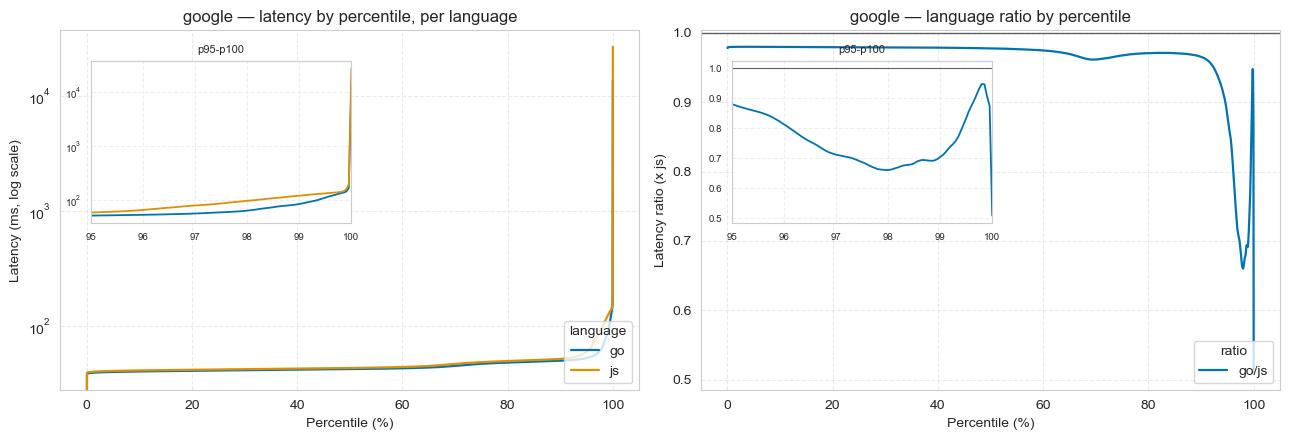

Saved: ./figures/language_tail_google.pdf


<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


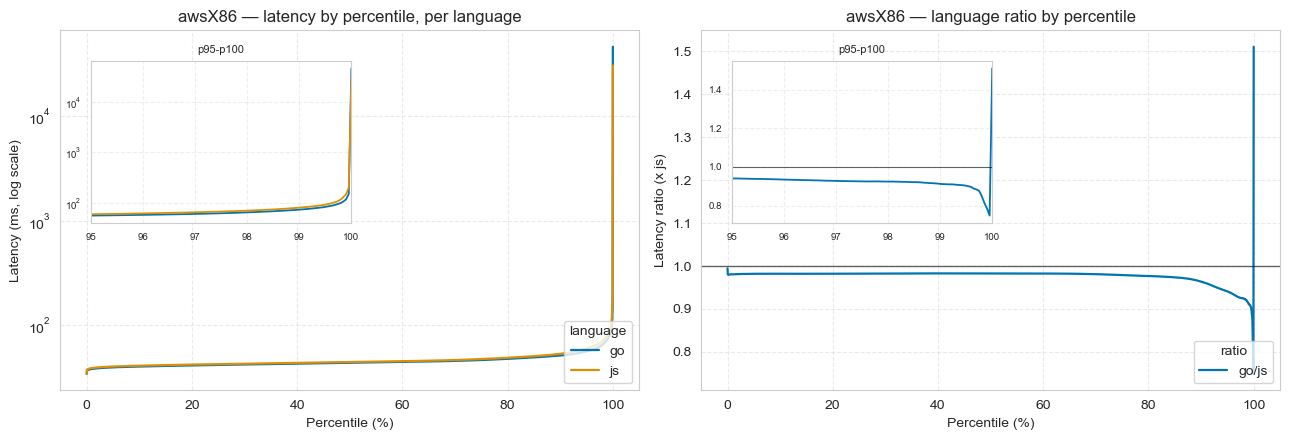

Saved: ./figures/language_tail_awsX86.pdf


<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


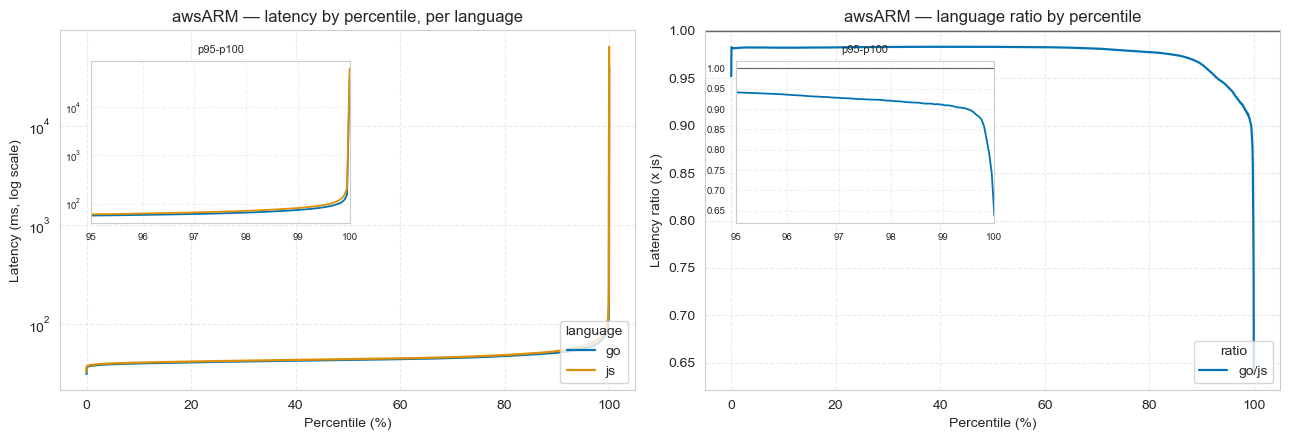

Saved: ./figures/language_tail_awsARM.pdf


<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


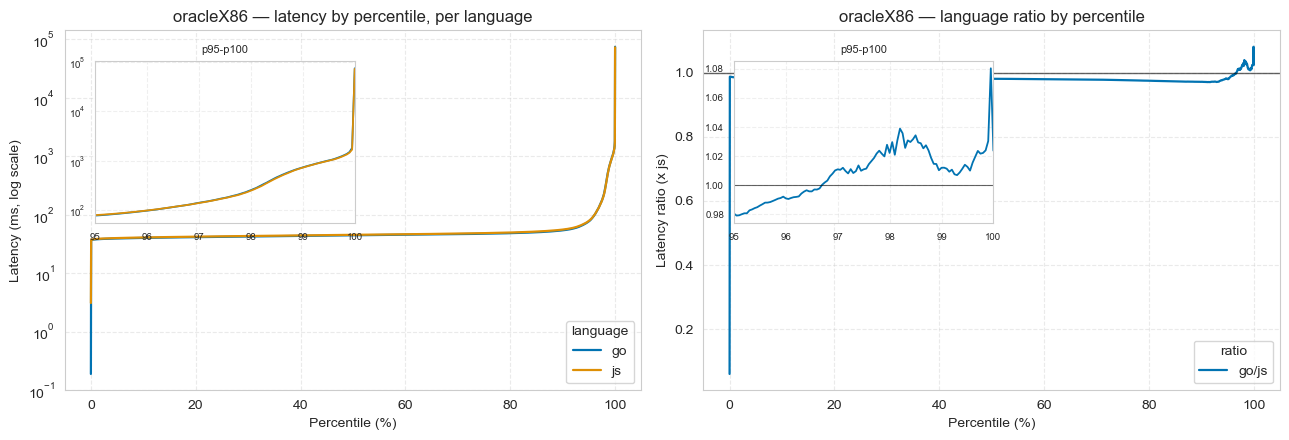

Saved: ./figures/language_tail_oracleX86.pdf


<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


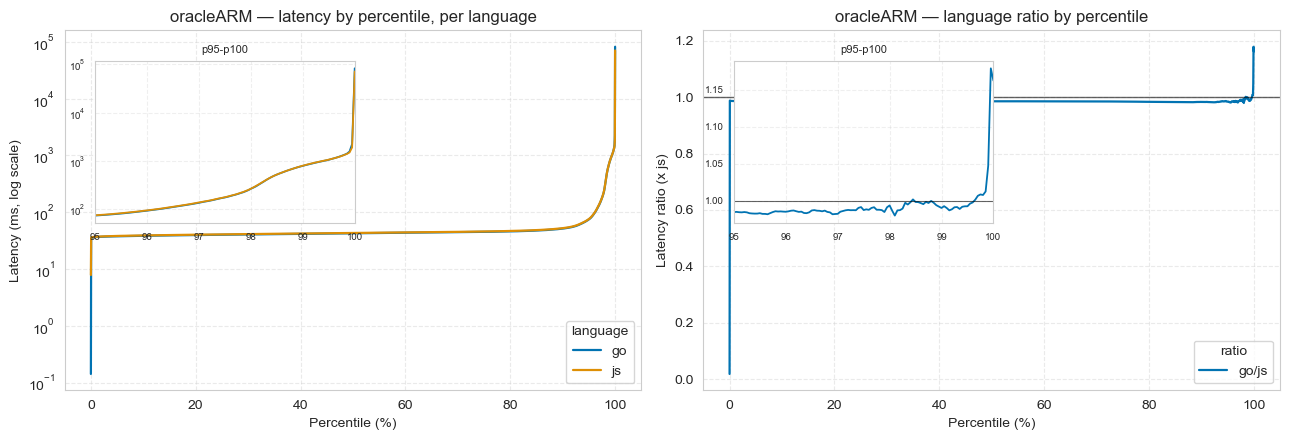

Saved: ./figures/language_tail_oracleARM.pdf


<notebook cell>:48: RuntimeWarning: invalid value encountered in divide
  ratio_curve = lang_curves[lang] / lang_curves[ref]
<notebook cell>:61: RuntimeWarning: invalid value encountered in divide
  ratio_curve = lang_curves[lang] / lang_curves[ref]
<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


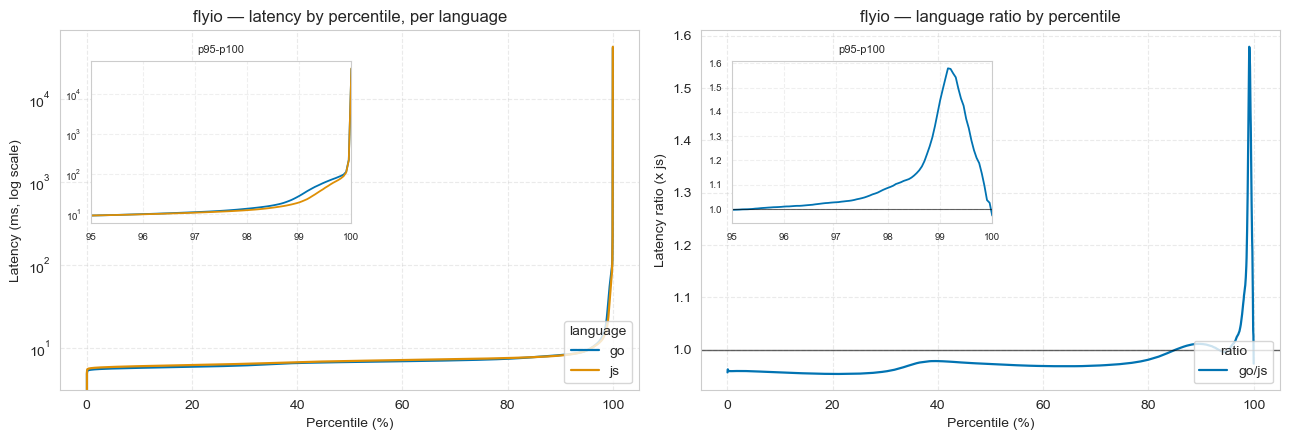

Saved: ./figures/language_tail_flyio.pdf


<notebook cell>:48: RuntimeWarning: invalid value encountered in divide
  ratio_curve = lang_curves[lang] / lang_curves[ref]
<notebook cell>:61: RuntimeWarning: invalid value encountered in divide
  ratio_curve = lang_curves[lang] / lang_curves[ref]
<notebook cell>:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


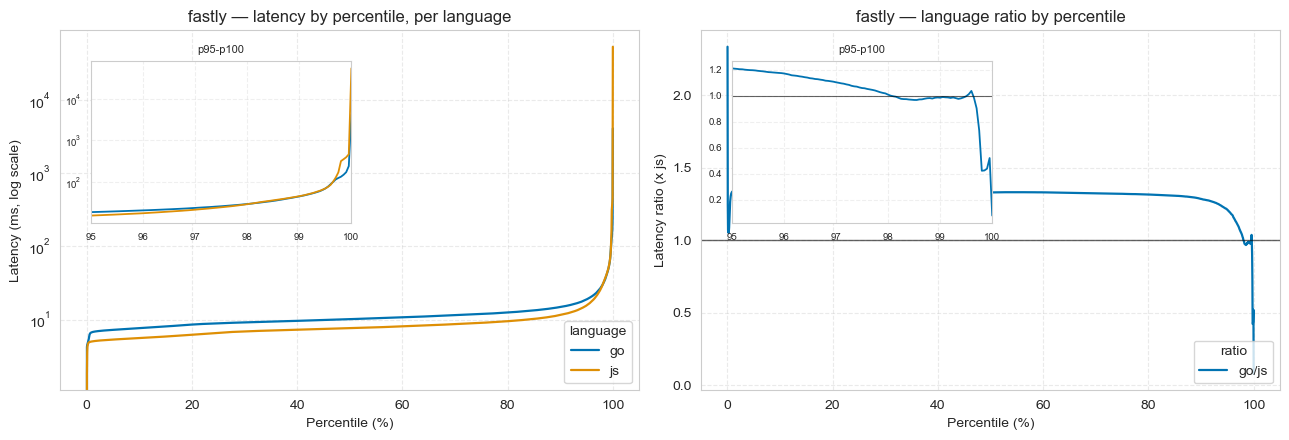

Saved: ./figures/language_tail_fastly.pdf


In [4]:

PERCENTILE_GRID = np.linspace(0.0, 100.0, 2001) / 100.0  # 0..100th, 0.05-pt resolution
SUMMARY_PERCENTILES = [50, 90, 95, 99, 99.9, 99.99]

os.makedirs("../figures/", exist_ok=True)
summary_rows = []

for provider in MULTI_LANG_PROVIDERS:
    df = provider_lang_data[provider]
    languages = sorted(df["language"].unique())
    if len(languages) < 2:
        print(f"{provider}: only one language present, skipping plot.")
        continue

    lang_values = {lang: df.loc[df["language"] == lang, "http_req_waiting"].to_numpy() for lang in languages}
    lang_curves = {lang: np.quantile(vals, PERCENTILE_GRID) for lang, vals in lang_values.items()}

    ref = REFERENCE_LANGUAGE if REFERENCE_LANGUAGE in lang_curves else languages[0]
    other_langs = [l for l in languages if l != ref]

    fig, (ax_pct, ax_ratio) = plt.subplots(1, 2, figsize=(13, 4.5))

    palette = sns.color_palette("colorblind", n_colors=len(languages))
    lang_color = dict(zip(languages, palette))

    # --- Left panel: percentile curve, one line per language ---
    for lang in languages:
        ax_pct.plot(PERCENTILE_GRID * 100, lang_curves[lang], label=lang, color=lang_color[lang], linewidth=1.6)
    ax_pct.set_yscale("log")
    ax_pct.set_xlabel("Percentile (%)")
    ax_pct.set_ylabel("Latency (ms, log scale)")
    ax_pct.set_title(f"{provider} — latency by percentile, per language")
    ax_pct.grid(True, linestyle="--", alpha=0.4)
    ax_pct.legend(title="language", loc="lower right")

    axins_pct = inset_axes(ax_pct, width="45%", height="45%", loc="upper left", borderpad=2.2)
    tail_mask = PERCENTILE_GRID >= 0.95
    for lang in languages:
        axins_pct.plot(PERCENTILE_GRID[tail_mask] * 100, lang_curves[lang][tail_mask],
                        color=lang_color[lang], linewidth=1.3)
    axins_pct.set_yscale("log")
    axins_pct.set_xlim(95, 100)
    axins_pct.set_title("p95-p100", fontsize=8)
    axins_pct.tick_params(labelsize=7)
    axins_pct.grid(True, linestyle="--", alpha=0.3)

    # --- Right panel: ratio curve, other language(s) / reference language ---
    for lang in other_langs:
        ratio_curve = lang_curves[lang] / lang_curves[ref]
        ax_ratio.plot(PERCENTILE_GRID * 100, ratio_curve, label=f"{lang}/{ref}",
                      color=lang_color[lang], linewidth=1.6)
    ax_ratio.axhline(1.0, color="black", linewidth=1, alpha=0.6)
    ax_ratio.set_xlabel("Percentile (%)")
    ax_ratio.set_ylabel(f"Latency ratio (x {ref})")
    ax_ratio.set_title(f"{provider} — language ratio by percentile")
    ax_ratio.grid(True, linestyle="--", alpha=0.4)
    if other_langs:
        ax_ratio.legend(title="ratio", loc="lower right")

    axins_ratio = inset_axes(ax_ratio, width="45%", height="45%", loc="upper left", borderpad=2.2)
    for lang in other_langs:
        ratio_curve = lang_curves[lang] / lang_curves[ref]
        axins_ratio.plot(PERCENTILE_GRID[tail_mask] * 100, ratio_curve[tail_mask],
                          color=lang_color[lang], linewidth=1.3)
    axins_ratio.axhline(1.0, color="black", linewidth=0.8, alpha=0.6)
    axins_ratio.set_xlim(95, 100)
    axins_ratio.set_title("p95-p100", fontsize=8)
    axins_ratio.tick_params(labelsize=7)
    axins_ratio.grid(True, linestyle="--", alpha=0.3)

    plt.tight_layout()
    out_path = f"../figures/language_tail_{provider}.pdf"
    fig.savefig(out_path, format="pdf", bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")

    # --- Summary table: point estimate + N + N_eff per language, at each percentile ---
    for lang in languages:
        vals = lang_values[lang]
        n = vals.size
        for p in SUMMARY_PERCENTILES:
            point = float(np.quantile(vals, p / 100.0))
            n_eff = n * (1 - p / 100.0)
            summary_rows.append({
                "provider": provider,
                "language": lang,
                "percentile": f"p{p}",
                "N": n,
                "N_eff": round(n_eff, 1),
                "low_confidence": n_eff < LOW_CONFIDENCE_THRESHOLD,
                "value_ms": round(point, 2),
            })

summary_df = pd.DataFrame(summary_rows)


## 4. Combined summary table

Point estimate, N, and N_eff (same `< 30` low-confidence convention as
`03_tail_percentile_robustness.ipynb`) for every provider x language x
percentile combination plotted above.

In [5]:

display(
    summary_df.style
    .apply(lambda row: ["background-color: #fde2e1" if row["low_confidence"] else "" for _ in row], axis=1)
    .format({"N": "{:,d}", "N_eff": "{:,.1f}", "value_ms": "{:,.2f}"})
)

summary_df.to_csv("../figures/language_tail_summary_table.csv", index=False)
print("Saved: ../figures/language_tail_summary_table.csv")


,provider,language,percentile,N,N_eff,low_confidence,value_ms
0,google,go,p50,"959,761","479,880.5",False,42.00
1,google,go,p90,"959,761","95,976.1",False,49.74
2,google,go,p95,"959,761","47,988.1",False,52.49
3,google,go,p99,"959,761","9,597.6",False,85.80
4,google,go,p99.9,"959,761",959.8,False,144.73
5,google,go,p99.99,"959,761",96.0,False,271.24
6,google,js,p50,"959,599","479,799.5",False,42.97
7,google,js,p90,"959,599","95,959.9",False,51.52
8,google,js,p95,"959,599","47,980.0",False,59.61
9,google,js,p99,"959,599","9,596.0",False,121.87


Saved: ./figures/language_tail_summary_table.csv


## 5. Ratio at the extreme percentiles, per provider

Pulls the `p99.9` / `p99.99` ratio (other language / `js`) directly out of
the curves above, so the headline "which language wins in the tail, and by
how much" numbers don't have to be read off a log-log plot by eye.

In [6]:

ratio_rows = []
for provider in MULTI_LANG_PROVIDERS:
    df = provider_lang_data[provider]
    languages = sorted(df["language"].unique())
    if len(languages) < 2:
        continue
    ref = REFERENCE_LANGUAGE if REFERENCE_LANGUAGE in languages else languages[0]
    other_langs = [l for l in languages if l != ref]
    for lang in other_langs:
        for p in [99.9, 99.99]:
            v_other = float(df.loc[df["language"] == lang, "http_req_waiting"].quantile(p / 100.0))
            v_ref = float(df.loc[df["language"] == ref, "http_req_waiting"].quantile(p / 100.0))
            ratio_rows.append({
                "provider": provider,
                "comparison": f"{lang}/{ref}",
                "percentile": f"p{p}",
                f"{lang}_ms": round(v_other, 2),
                f"{ref}_ms": round(v_ref, 2),
                "ratio": round(v_other / v_ref, 3) if v_ref else np.nan,
            })

ratio_df = pd.DataFrame(ratio_rows)
display(ratio_df)


,provider,comparison,percentile,go_ms,js_ms,ratio
0,google,go/js,p99.9,144.73,159.54,0.907
1,google,go/js,p99.99,271.24,284.18,0.954
2,awsX86,go/js,p99.9,117.99,150.28,0.785
3,awsX86,go/js,p99.99,550.87,512.85,1.074
4,awsARM,go/js,p99.9,119.54,151.16,0.791
5,awsARM,go/js,p99.99,480.71,708.05,0.679
6,oracleX86,go/js,p99.9,1499.60,1455.33,1.030
7,oracleX86,go/js,p99.99,6300.33,4216.28,1.494
8,oracleARM,go/js,p99.9,1572.45,1501.30,1.047
9,oracleARM,go/js,p99.99,17062.49,10239.32,1.666
